# 📱 App Insights Unlocked: Google Play Store EDA

**Role:** Data Analyst at a mobile-app company
**Goal:** Find out what drives app success (ratings, installs, reviews) and turn it into app-development recommendations.

**Dataset:** `googleplaystore.csv` (Kaggle – Google Play Store Apps)

**Stakeholders:** App Developers · Product Managers · Marketing · Senior Management (internal) | Users · Advertisers · Partners (external)

---
### Notebook roadmap
1. Setup & data loading
2. First look at the data
3. Data cleaning & preprocessing
4. Metric development (what is "success"?)
5. Basic-level questions (Q1–Q10)
6. Medium-level questions (Q1–Q10)
7. Advanced-level questions (Q1–Q5)
8. Key insights & recommendations

## 1. Setup & Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, os
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

**Loading the file in Google Colab** – run the next cell and click *Choose Files* to upload `googleplaystore.csv`.
(Alternative: mount Google Drive and change `FILE_PATH`.)

In [2]:
FILE_PATH = 'googleplaystore.csv'

# --- Option A: upload directly in Colab ---
if not os.path.exists(FILE_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()          # pick googleplaystore.csv
        FILE_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError('Put googleplaystore.csv next to the notebook or update FILE_PATH.')

# --- Option B: Google Drive (uncomment) ---
# from google.colab import drive
# drive.mount('/content/drive')
# FILE_PATH = '/content/drive/MyDrive/googleplaystore.csv'

df_raw = pd.read_csv(FILE_PATH)
print('Raw shape:', df_raw.shape)
df_raw.head()

Raw shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.100,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.900,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.700,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.500,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.300,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## 2. First Look at the Data

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


In [4]:
print('Missing values per column:')
print(df_raw.isna().sum())
print('\nFully duplicated rows :', df_raw.duplicated().sum())
print('Duplicated App names  :', df_raw['App'].duplicated().sum())

Missing values per column:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Fully duplicated rows : 483
Duplicated App names  : 1181


**What we notice**
- `Rating` has ~1,474 missing values (apps with no ratings yet).
- Almost every numeric column (`Reviews`, `Size`, `Installs`, `Price`) is stored as **text** (`"10,000+"`, `"$4.99"`, `"19M"`).
- There are many **duplicate rows** and repeated app names.
- One row looks corrupted (its `Category` is `1.9`, which is a rating – the columns are shifted). Let's confirm.

In [5]:
df_raw[~df_raw['Category'].str.isupper().fillna(False)]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.000,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


## 3. Data Cleaning & Preprocessing
Steps (matching the case-study checklist): **missing values → data types → duplicates → text standardisation → dates**.

In [6]:
df = df_raw.copy()

# 0. Remove the corrupted (column-shifted) row ---------------------------------
bad = df['Category'] == '1.9'
print(f'Corrupted rows removed: {bad.sum()}')
df = df[~bad].copy()

# 1. Remove duplicates -----------------------------------------------------------
n0 = len(df)
df = df.drop_duplicates()
print(f'Exact duplicate rows removed: {n0 - len(df)}')

# Same app listed several times with different review counts -> keep the most-reviewed (latest) record
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')
n1 = len(df)
df = (df.sort_values('Reviews', ascending=False)
        .drop_duplicates(subset='App', keep='first')
        .sort_index())
print(f'Repeated App names removed (kept max Reviews): {n1 - len(df)}')
print('Rows now:', len(df))

Corrupted rows removed: 1
Exact duplicate rows removed: 483
Repeated App names removed (kept max Reviews): 698
Rows now: 9659


In [7]:
# 2. Convert data types ----------------------------------------------------------
# Installs: "10,000+" -> 10000
df['Installs'] = (df['Installs'].str.replace('[+,]', '', regex=True).astype('int64'))

# Price: "$4.99" -> 4.99
df['Price'] = df['Price'].str.replace('$', '', regex=False).astype(float)

# Size: "19M" -> 19.0 (MB), "512k" -> 0.5 (MB), "Varies with device" -> NaN
def size_to_mb(s):
    if s.endswith('M'):
        return float(s[:-1])
    if s.endswith('k'):
        return float(s[:-1]) / 1024
    return np.nan                       # 'Varies with device'
df['Size_MB'] = df['Size'].apply(size_to_mb)

# Last Updated -> datetime
df['Last Updated'] = pd.to_datetime(df['Last Updated'], format='%B %d, %Y', errors='coerce')
df['Update_Year']  = df['Last Updated'].dt.year
df['Update_Month'] = df['Last Updated'].dt.month

df[['Reviews','Installs','Price','Size_MB','Last Updated']].dtypes

Reviews                  int64
Installs                 int64
Price                  float64
Size_MB                float64
Last Updated    datetime64[us]
dtype: object

In [8]:
# 3. Handle missing values ---------------------------------------------------------
print('Missing before:'); print(df.isna().sum()[lambda s: s > 0]); print()

# Type: the one missing value has Price 0 -> Free
df.loc[df['Type'].isna(), 'Type'] = np.where(df.loc[df['Type'].isna(), 'Price'] == 0, 'Free', 'Paid')

# Content Rating / Android Ver / Current Ver -> small gaps, fill with 'Unknown' (not used numerically)
for c in ['Content Rating', 'Current Ver', 'Android Ver']:
    df[c] = df[c].fillna('Unknown')

# Rating: NOT imputed. A missing rating means 'nobody rated it yet'; filling it with the mean
# would invent data and distort every rating-based analysis. Rating analyses use dropna().
# Size_MB: 'Varies with device' stays NaN for the same reason.
print('Missing after:'); print(df.isna().sum()[lambda s: s > 0])

Missing before:
Rating         1463
Type              1
Current Ver       8
Android Ver       2
Size_MB        1228
dtype: int64

Missing after:
Rating     1463
Size_MB    1228
dtype: int64


In [9]:
# 4. Standardise text --------------------------------------------------------------
df['Category'] = df['Category'].str.replace('_', ' ').str.title().str.strip()
df['Genres']   = df['Genres'].str.strip()
df['Primary_Genre'] = df['Genres'].str.split(';').str[0].str.strip()   # 'Art & Design;Pretend Play' -> 'Art & Design'
df['Content Rating'] = df['Content Rating'].str.strip()
df['Type'] = df['Type'].str.strip().str.title()

# Helper columns used later
df['Log_Installs'] = np.log10(df['Installs'].replace(0, np.nan))
df['Log_Reviews']  = np.log10(df['Reviews'].replace(0, np.nan))
df['Is_Free']      = (df['Type'] == 'Free')

print('Clean shape:', df.shape)
df.head()

Clean shape: (9659, 20)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB,Update_Year,Update_Month,Primary_Genre,Log_Installs,Log_Reviews,Is_Free
0,Photo Editor & Candy Camera & Grid & ScrapBook,Art And Design,4.100,159,19M,10000,Free,0.000,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up,19.000,2018,1,Art & Design,4.000,2.201,True
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",Art And Design,4.700,87510,8.7M,5000000,Free,0.000,Everyone,Art & Design,2018-08-01,1.2.4,4.0.3 and up,8.700,2018,8,Art & Design,6.699,4.942,True
3,Sketch - Draw & Paint,Art And Design,4.500,215644,25M,50000000,Free,0.000,Teen,Art & Design,2018-06-08,Varies with device,4.2 and up,25.000,2018,6,Art & Design,7.699,5.334,True
4,Pixel Draw - Number Art Coloring Book,Art And Design,4.300,967,2.8M,100000,Free,0.000,Everyone,Art & Design;Creativity,2018-06-20,1.1,4.4 and up,2.800,2018,6,Art & Design,5.000,2.985,True
5,Paper flowers instructions,Art And Design,4.400,167,5.6M,50000,Free,0.000,Everyone,Art & Design,2017-03-26,1.0,2.3 and up,5.600,2017,3,Art & Design,4.699,2.223,True


In [10]:
# Sanity checks
assert df['App'].is_unique
assert df['Rating'].dropna().between(1, 5).all()
print('Type values     :', df['Type'].unique())
print('Categories      :', df['Category'].nunique())
print('Date range      :', df['Last Updated'].min().date(), '->', df['Last Updated'].max().date())
df.describe().T

Type values     : <StringArray>
['Free', 'Paid']
Length: 2, dtype: str
Categories      : 33
Date range      : 2010-05-21 -> 2018-08-08


,count,mean,min,25%,50%,75%,max,std
Rating,"8,196.000",4.173,1.000,4.000,4.300,4.500,5.000,0.536
Reviews,"9,659.000","216,804.110",0.000,25.000,969.000,"29,453.500","78,158,306.000","1,831,430.213"
Installs,"9,659.000","7,798,170.248",0.000,"1,000.000","100,000.000","1,000,000.000","1,000,000,000.000","53,769,728.818"
Price,"9,659.000",1.097,0.000,0.000,0.000,0.000,400.000,16.852
Last Updated,9659,2017-10-30 23:43:36.047209,2010-05-21 00:00:00,2017-08-07 00:00:00,2018-05-04 00:00:00,2018-07-17 00:00:00,2018-08-08 00:00:00,NaN
Size_MB,"8,431.000",20.398,0.008,4.600,12.000,28.000,100.000,21.829
Update_Year,"9,659.000","2,017.346","2,010.000","2,017.000","2,018.000","2,018.000","2,018.000",1.137
Update_Month,"9,659.000",6.364,1.000,5.000,7.000,8.000,12.000,2.660
Log_Installs,"9,644.000",4.650,0.000,3.000,5.000,6.000,9.000,1.903
Log_Reviews,"9,066.000",3.140,0.000,1.681,3.208,4.538,7.893,1.736


✅ **Cleaning summary:** the raw 10,841 rows become ~9,659 unique apps. Numeric columns are now numeric, `Last Updated` is a real datetime, and missing ratings were deliberately left as `NaN` rather than faked.

## 4. Metric Development – defining "App Success"
The case study asks for success metrics such as average rating, total installs and number of reviews. We use three **core metrics** and one **combined score**:

| Metric | Meaning |
|---|---|
| **Average Rating** | User satisfaction (quality) |
| **Total Installs** | Reach / popularity (installs are bucketed – `1,000+` etc. – so we use the lower bound) |
| **Reviews** | User engagement |
| **Success Score (0-100)** | Average of percentile ranks of Rating, log-Installs and log-Reviews – a single number to compare apps/categories |

In [11]:
rated = df.dropna(subset=['Rating']).copy()
rated['Success_Score'] = 100 * (rated['Rating'].rank(pct=True)
                                + rated['Installs'].rank(pct=True)
                                + rated['Reviews'].rank(pct=True)) / 3
df = df.merge(rated[['App','Success_Score']], on='App', how='left')

summary = pd.DataFrame({
    'Apps': [len(df)],
    'Avg Rating': [df['Rating'].mean()],
    'Median Installs': [df['Installs'].median()],
    'Total Installs (bn)': [df['Installs'].sum()/1e9],
    'Avg Reviews': [df['Reviews'].mean()],
    '% Free': [df['Is_Free'].mean()*100],
})
summary.T.rename(columns={0: 'Value'})

,Value
Apps,"9,659.000"
Avg Rating,4.173
Median Installs,"100,000.000"
Total Installs (bn),75.323
Avg Reviews,"216,804.110"
% Free,92.194


In [12]:
# Category scorecard using the success metrics
scorecard = (df.groupby('Category')
               .agg(Apps=('App','count'),
                    Avg_Rating=('Rating','mean'),
                    Total_Installs=('Installs','sum'),
                    Avg_Reviews=('Reviews','mean'),
                    Avg_Success_Score=('Success_Score','mean'))
               .sort_values('Avg_Success_Score', ascending=False))
scorecard.head(10)

,Apps,Avg_Rating,Total_Installs,Avg_Reviews,Avg_Success_Score
Category,,,,,
Entertainment,86,4.129,984660000,"296,841.872",62.550
Game,946,4.245,13457924415,"624,494.915",60.633
Education,106,4.351,189951000,"55,262.198",60.269
Weather,79,4.243,361100520,"155,636.025",59.004
Photography,281,4.156,4658147655,"375,731.217",58.825
Shopping,202,4.231,1400348785,"220,564.688",58.124
Health And Fitness,288,4.243,1144022512,"74,186.528",55.343
Food And Drink,112,4.171,211798751,"56,482.714",55.012
Social,239,4.247,5487867902,"953,708.598",54.866


## 5. Basic-Level Questions

### Q1. What is the average rating of apps?

Average rating : 4.17
Median rating  : 4.30
Apps with a rating: 8,196 of 9,659


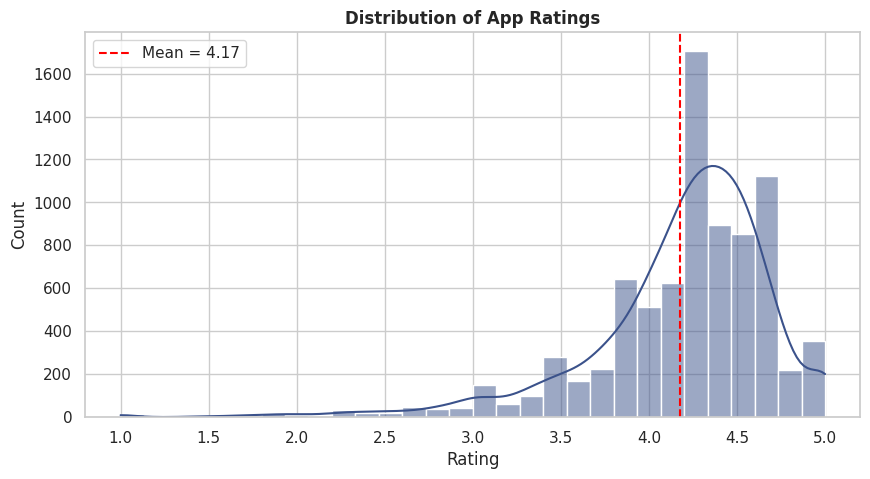

In [13]:
avg_rating = df['Rating'].mean()
print(f'Average rating : {avg_rating:.2f}')
print(f'Median rating  : {df["Rating"].median():.2f}')
print(f'Apps with a rating: {df["Rating"].notna().sum():,} of {len(df):,}')

sns.histplot(df['Rating'].dropna(), bins=30, kde=True, color='#3b528b')
plt.axvline(avg_rating, color='red', ls='--', label=f'Mean = {avg_rating:.2f}')
plt.title('Distribution of App Ratings'); plt.xlabel('Rating'); plt.legend(); plt.show()

**Insight:** Ratings are strongly left-skewed – most apps sit between 4.0 and 4.7. A rating of ~4.2 is the *benchmark*; anything below ~4.0 is below market norm.

### Q2. How many unique categories are there?

Unique categories: 33


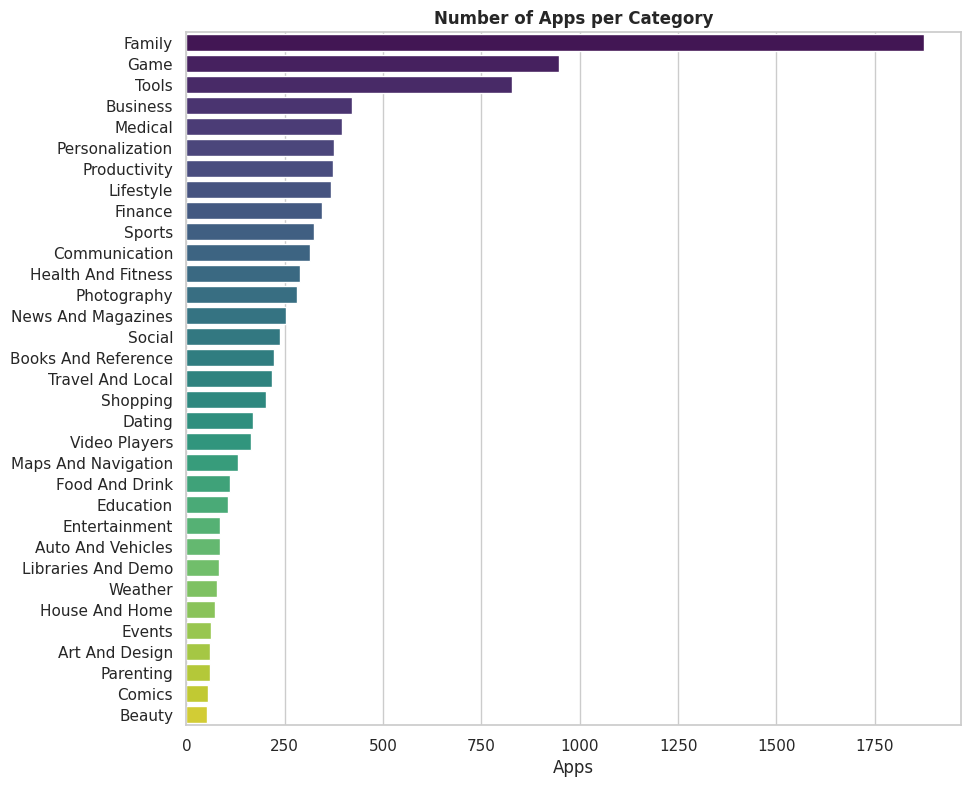

Category
Family      1876
Game         946
Tools        829
Business     420
Medical      395
Name: count, dtype: int64

In [14]:
print('Unique categories:', df['Category'].nunique())
cat_counts = df['Category'].value_counts()
plt.figure(figsize=(10, 9))
sns.barplot(x=cat_counts.values, y=cat_counts.index, palette='viridis')
plt.title('Number of Apps per Category'); plt.xlabel('Apps'); plt.ylabel('')
plt.show()
cat_counts.head(5)

**Insight:** The market is dominated by **Family, Game and Tools**; niche categories (Beauty, Comics, Parenting, Art & Design, Events) have only ~50-65 apps each – potentially less crowded.

### Q3. Distribution of app sizes

count   8,431.000
mean       20.398
std        21.829
min         0.008
25%         4.600
50%        12.000
75%        28.000
max       100.000
Name: Size_MB, dtype: float64

'Varies with device' (no fixed size): 1,228 apps


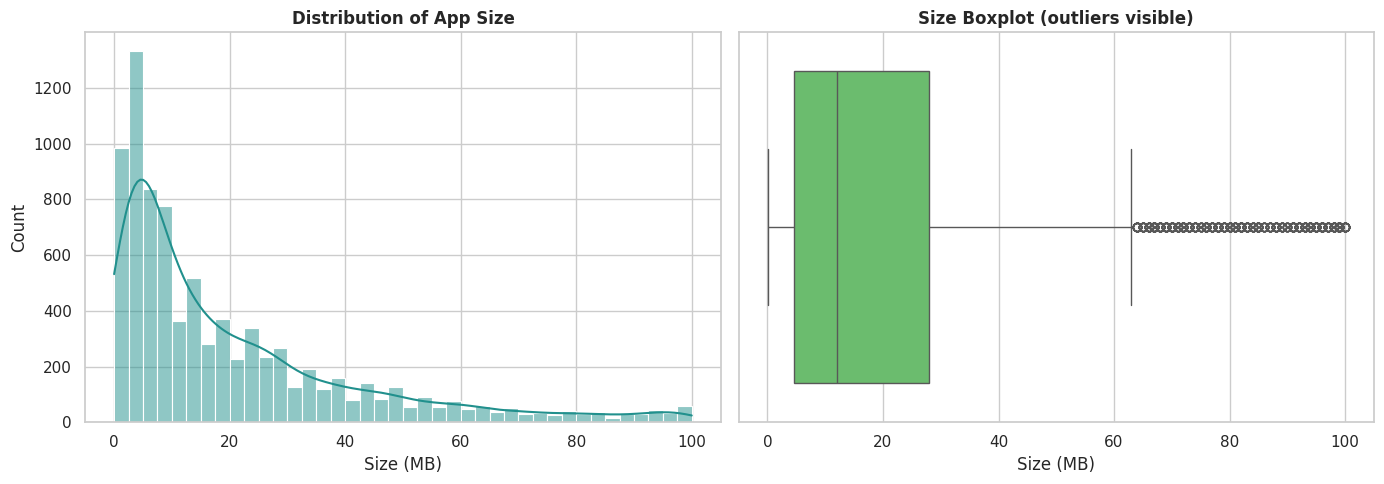

In [15]:
print(df['Size_MB'].describe())
print(f"\n'Varies with device' (no fixed size): {df['Size_MB'].isna().sum():,} apps")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Size_MB'].dropna(), bins=40, kde=True, ax=ax[0], color='#21908d')
ax[0].set_title('Distribution of App Size'); ax[0].set_xlabel('Size (MB)')
sns.boxplot(x=df['Size_MB'].dropna(), ax=ax[1], color='#5ec962')
ax[1].set_title('Size Boxplot (outliers visible)'); ax[1].set_xlabel('Size (MB)')
plt.tight_layout(); plt.show()

**Insight:** Most apps are small – the median is roughly 12–13 MB – with a long tail of heavy apps (mostly games) up to 100 MB. Design for lean installs unless the content (e.g., 3D graphics) demands more.

### Q4. Free vs Paid apps

Type
Free    8905
Paid     754
Name: count, dtype: int64
Type
Free    92.2%
Paid     7.8%
Name: count, dtype: str


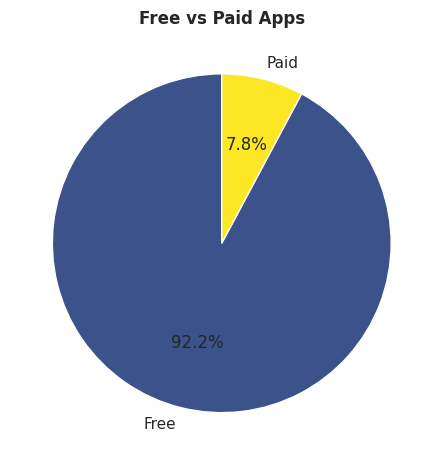

In [16]:
type_counts = df['Type'].value_counts()
print(type_counts)
print((type_counts / type_counts.sum() * 100).round(1).astype(str) + '%')

plt.figure(figsize=(5.5, 5.5))
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', startangle=90,
        colors=['#3b528b', '#fde725'], wedgeprops={'edgecolor': 'white'})
plt.title('Free vs Paid Apps'); plt.show()

**Insight:** ~92% of apps are free, so free + monetisation (ads / in-app purchases) is the default business model. Paid apps need a clear value proposition.

### Q5. Most common content rating

Mode: Everyone


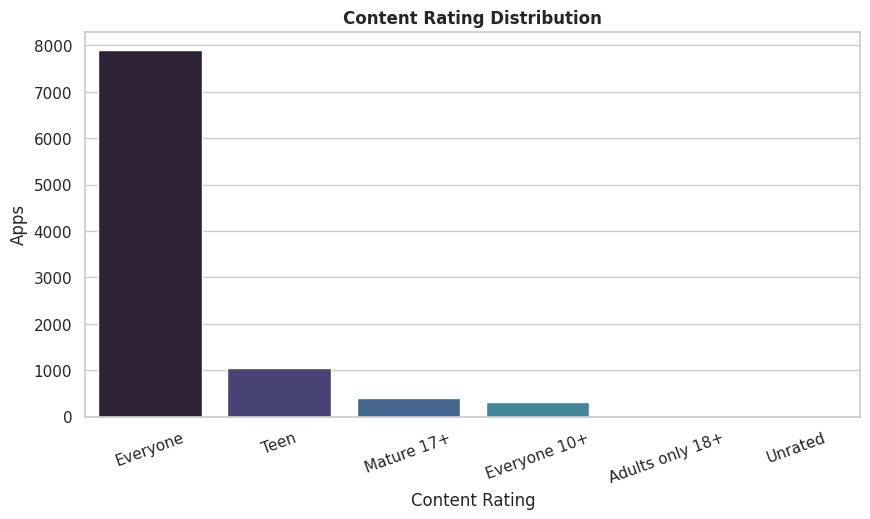

Content Rating
Everyone           7903
Teen               1036
Mature 17+          393
Everyone 10+        322
Adults only 18+       3
Unrated               2
Name: count, dtype: int64

In [17]:
cr = df['Content Rating'].value_counts()
print('Mode:', df['Content Rating'].mode()[0])
sns.barplot(x=cr.index, y=cr.values, palette='mako')
plt.title('Content Rating Distribution'); plt.xticks(rotation=20); plt.ylabel('Apps'); plt.show()
cr

**Insight:** *Everyone* is by far the most common content rating, i.e. the biggest addressable audience. Restricted ratings (Mature 17+, Adults only) are a small niche.

### Q6. Top 5 most-installed apps

In [18]:
top_installed = df.sort_values('Installs', ascending=False)[['App','Category','Installs','Rating','Reviews']]
print('Apps in the top install bucket (1B+):', (df['Installs'] == df['Installs'].max()).sum())
top_installed.head(5)

Apps in the top install bucket (1B+): 20


,App,Category,Installs,Rating,Reviews
1873,Facebook,Social,1000000000,4.100,78158306
1879,Google+,Social,1000000000,4.200,4831125
359,Hangouts,Communication,1000000000,4.000,3419513
2105,Google Photos,Photography,1000000000,4.500,10859051
347,Gmail,Communication,1000000000,4.300,4604483


**Note:** Installs are *bucketed* (1,000,000,000+ is the highest bucket), so many apps tie for first place. The table above shows five of them – use `Reviews` as a tie-breaker (below) to find the biggest by engagement.

In [19]:
(df[df['Installs'] == df['Installs'].max()]
   .sort_values('Reviews', ascending=False)[['App','Category','Installs','Rating','Reviews']]
   .head(10))

,App,Category,Installs,Rating,Reviews
1873,Facebook,Social,1000000000,4.100,78158306
279,WhatsApp Messenger,Communication,1000000000,4.400,69119316
1914,Instagram,Social,1000000000,4.500,66577446
304,Messenger – Text and Video Chat for Free,Communication,1000000000,4.000,56646578
1350,Subway Surfers,Game,1000000000,4.500,27725352
2749,YouTube,Video Players,1000000000,4.300,25655305
2105,Google Photos,Photography,1000000000,4.500,10859051
308,Skype - free IM & video calls,Communication,1000000000,4.100,10484169
320,Google Chrome: Fast & Secure,Communication,1000000000,4.300,9643041
2342,Maps - Navigate & Explore,Travel And Local,1000000000,4.300,9235373


### Q7. How many apps are rated 4.0 and above?

In [20]:
high = (df['Rating'] >= 4.0).sum()
rated_total = df['Rating'].notna().sum()
print(f'Apps rated >= 4.0 : {high:,}')
print(f'Share of rated apps: {high/rated_total:.1%}   |   share of all apps: {high/len(df):.1%}')

Apps rated >= 4.0 : 6,287
Share of rated apps: 76.7%   |   share of all apps: 65.1%


**Insight:** About **77% of rated apps score 4.0+** (6,287 apps). High ratings are the norm, so a 4.0 won't differentiate you – aim for 4.3+ (the median).

### Q8. Average reviews: Free vs Paid

      count        mean    median
Type                             
Free   8905 234,420.539 1,379.000
Paid    754   8,748.011    88.500


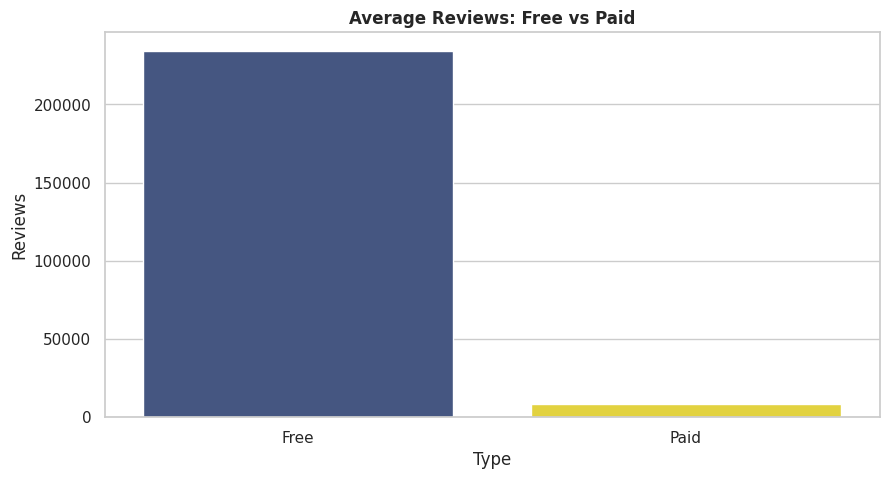

In [21]:
rv = df.groupby('Type')['Reviews'].agg(['count','mean','median'])
print(rv)
sns.barplot(data=df, x='Type', y='Reviews', estimator=np.mean, errorbar=None, palette=['#3b528b','#fde725'])
plt.title('Average Reviews: Free vs Paid'); plt.show()

**Insight:** Free apps attract far more reviews on average (and at the median) – lower friction means more users, which means more feedback.

### Q9. Average app size per category

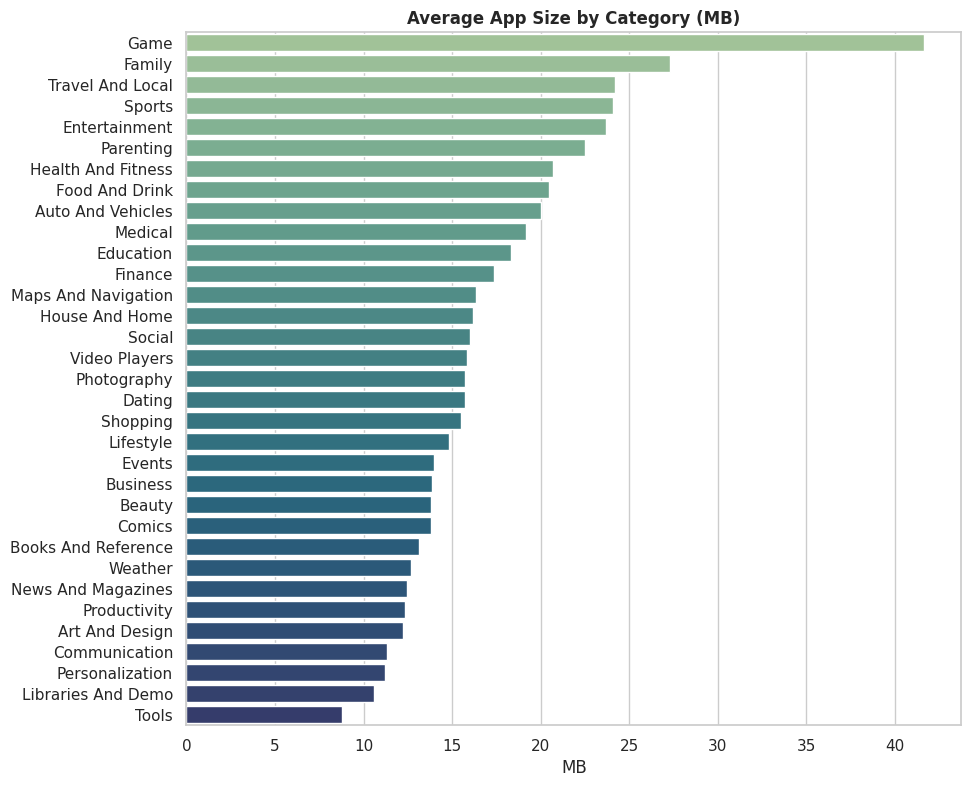

Category
Game               41.657
Family             27.322
Travel And Local   24.204
Sports             24.058
Entertainment      23.707
Name: Size_MB, dtype: float64

In [22]:
size_cat = df.groupby('Category')['Size_MB'].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 9))
sns.barplot(x=size_cat.values, y=size_cat.index, palette='crest')
plt.title('Average App Size by Category (MB)'); plt.xlabel('MB'); plt.ylabel('')
plt.show()
size_cat.head(5)

**Insight:** **Games (~42 MB)** and Family (~27 MB) are by far the heaviest (media-rich); Tools (~9 MB), Libraries & Demo and Personalization (~11 MB) are the lightest.

### Q10. Apps last updated in 2018

In [23]:
n2018 = (df['Update_Year'] == 2018).sum()
print(f'Apps last updated in 2018: {n2018:,}  ({n2018/len(df):.1%} of all apps)')
df['Update_Year'].value_counts().sort_index()

Apps last updated in 2018: 6,287  (65.1% of all apps)


Update_Year
2010       1
2011      15
2012      26
2013     108
2014     203
2015     448
2016     779
2017    1792
2018    6287
Name: count, dtype: int64

**Insight:** A very large share of apps were updated in 2018 – the dataset was scraped in mid-2018, so this shows that the successful apps are *actively maintained*.

## 6. Medium-Level Questions

### Q1. Correlation between installs and rating

Pearson  (raw installs)  : 0.040
Pearson  (log10 installs): 0.084
Spearman (rank-based)    : 0.027


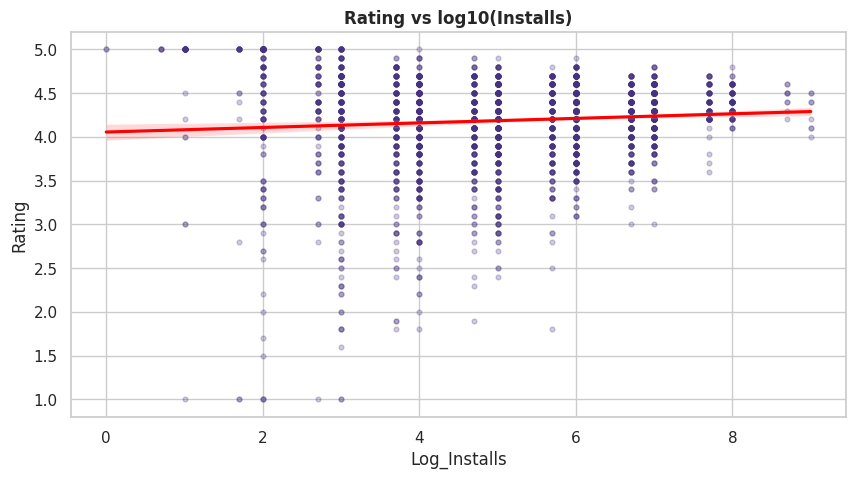

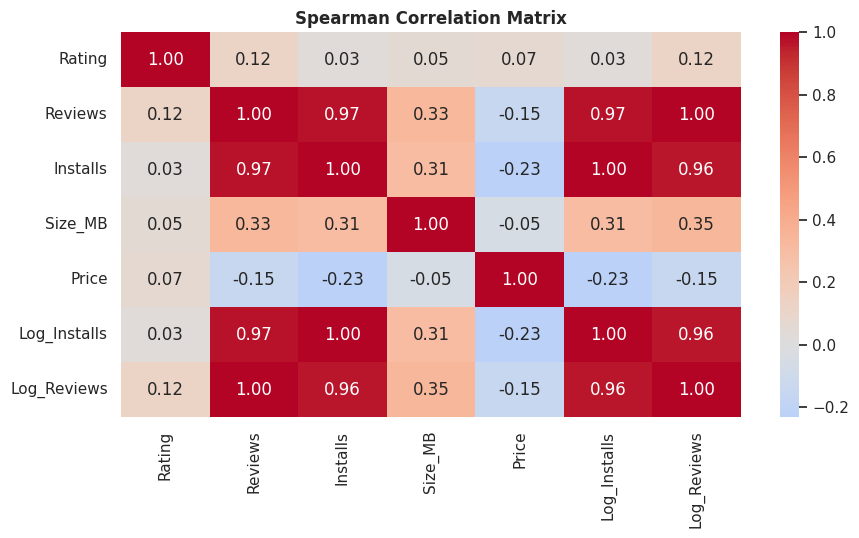

In [24]:
sub = df.dropna(subset=['Rating'])
pearson  = sub['Installs'].corr(sub['Rating'])
spearman = sub['Installs'].corr(sub['Rating'], method='spearman')
print(f'Pearson  (raw installs)  : {pearson:.3f}')
print(f'Pearson  (log10 installs): {sub["Log_Installs"].corr(sub["Rating"]):.3f}')
print(f'Spearman (rank-based)    : {spearman:.3f}')

sns.regplot(data=sub.sample(3000, random_state=1), x='Log_Installs', y='Rating',
            scatter_kws={'alpha': .25, 's': 12}, line_kws={'color': 'red'})
plt.title('Rating vs log10(Installs)'); plt.show()

# Wider correlation heatmap
num = df[['Rating','Reviews','Installs','Size_MB','Price','Log_Installs','Log_Reviews']].corr(method='spearman')
sns.heatmap(num, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Spearman Correlation Matrix'); plt.show()

**Insight:** The correlation between installs and rating is **very weak (≈0.03–0.08)**. Popularity does *not* guarantee quality – and quality alone doesn't create popularity. Installs correlate almost perfectly with reviews (Spearman ≈ 0.97), so reviews are essentially an engagement proxy for reach.

### Q2. Categories with the highest average rating

,mean,median,count
Category,,,
Events,4.436,4.500,45
Art And Design,4.359,4.400,59
Education,4.351,4.400,105
Books And Reference,4.345,4.500,169
Personalization,4.332,4.400,298
Parenting,4.300,4.400,50
Beauty,4.279,4.300,42
Social,4.247,4.300,203
Game,4.245,4.300,899


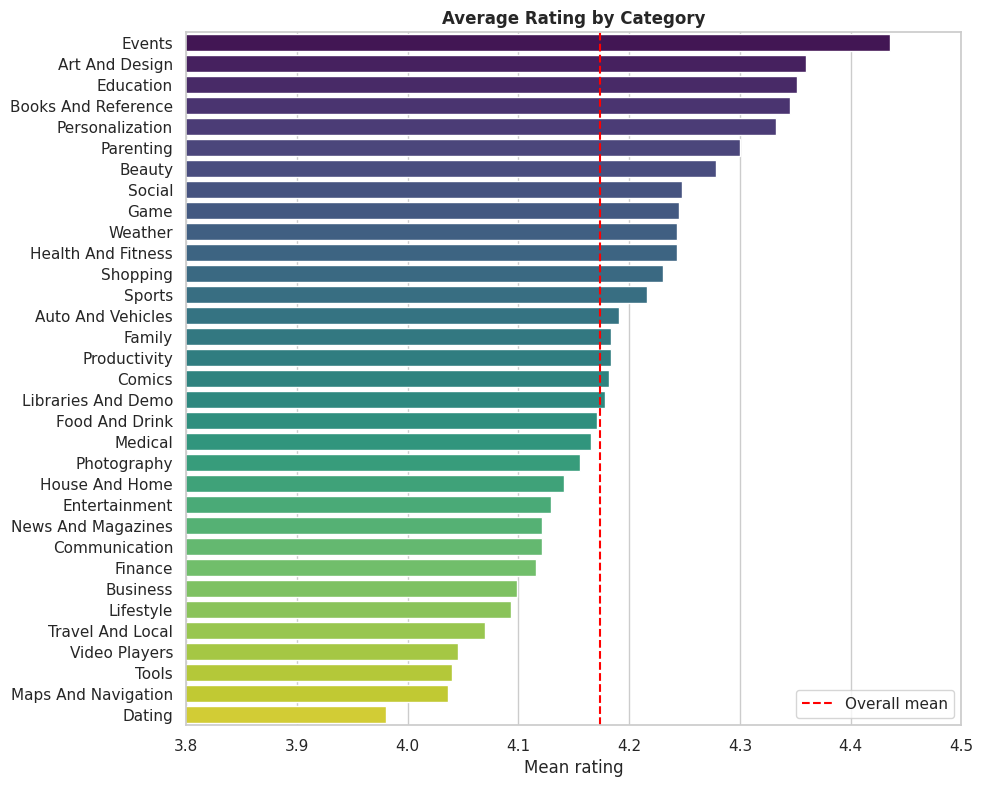

In [25]:
cat_rating = (df.groupby('Category')['Rating'].agg(['mean','median','count'])
                .sort_values('mean', ascending=False))
display(cat_rating.head(10))

plt.figure(figsize=(10, 9))
sns.barplot(x=cat_rating['mean'], y=cat_rating.index, palette='viridis')
plt.xlim(3.8, 4.5); plt.axvline(df['Rating'].mean(), color='red', ls='--', label='Overall mean')
plt.title('Average Rating by Category'); plt.xlabel('Mean rating'); plt.ylabel(''); plt.legend(); plt.show()

**Insight:** Events (4.44), Art & Design, Education, Books & Reference and Personalization lead; Dating (3.98), Maps & Navigation and Tools trail. The gap between best and worst is ~0.45 stars, so category matters but is not decisive.

### Q3. Does price affect rating? (paid apps only)

Paid, rated apps: 602
Price – Rating Spearman correlation: -0.096


,mean,median,count
Price_Band,,,
<= $1,4.301,4.400,106
$1-2,4.292,4.400,101
$2-5,4.264,4.400,282
$5-10,4.259,4.400,58
> $10,4.127,4.200,55


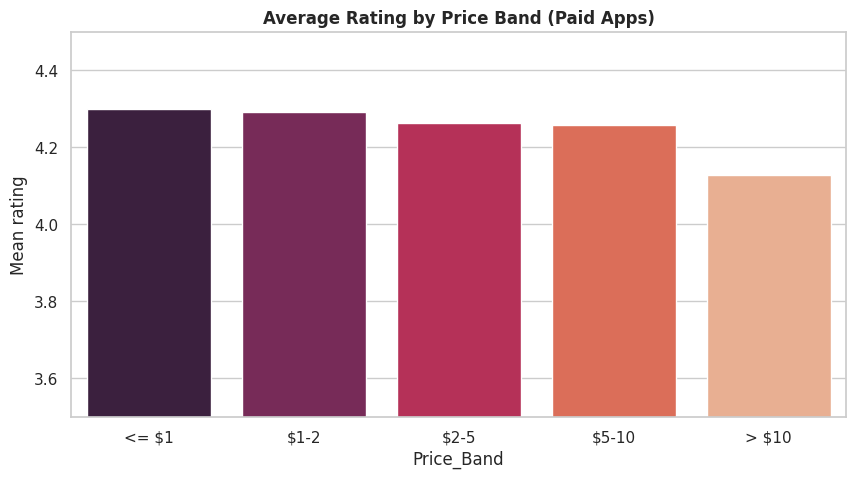

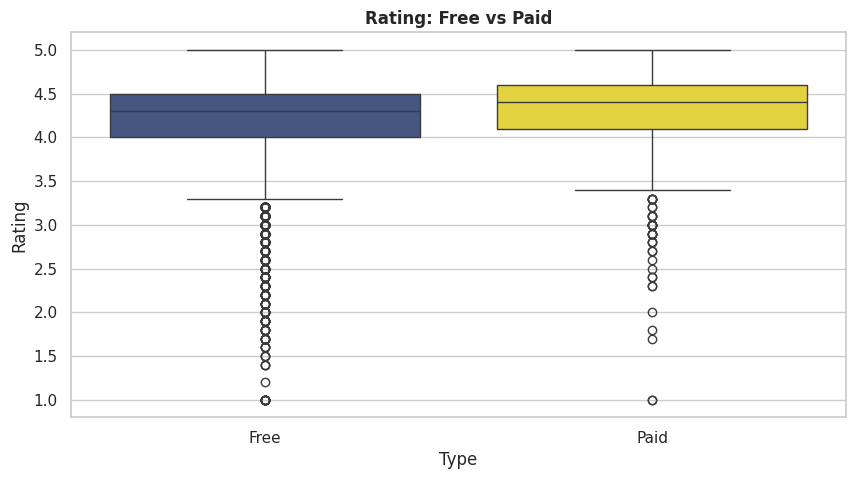

Type
Free   4.166
Paid   4.262
Name: Rating, dtype: float64


In [26]:
paid = df[(df['Type'] == 'Paid') & df['Rating'].notna()].copy()
print('Paid, rated apps:', len(paid))
print('Price – Rating Spearman correlation:', round(paid['Price'].corr(paid['Rating'], method='spearman'), 3))

paid['Price_Band'] = pd.cut(paid['Price'], bins=[0, 1, 2, 5, 10, 1000],
                            labels=['<= $1', '$1-2', '$2-5', '$5-10', '> $10'])
band = paid.groupby('Price_Band', observed=True)['Rating'].agg(['mean','median','count'])
display(band)

sns.barplot(x=band.index, y=band['mean'], palette='rocket')
plt.ylim(3.5, 4.5); plt.title('Average Rating by Price Band (Paid Apps)'); plt.ylabel('Mean rating'); plt.show()

# Free vs Paid
sns.boxplot(data=df.dropna(subset=['Rating']), x='Type', y='Rating', palette=['#3b528b','#fde725'])
plt.title('Rating: Free vs Paid'); plt.show()
print(df.groupby('Type')['Rating'].mean())

**Insight:** Paid apps are rated *slightly higher* than free apps (4.26 vs 4.17 mean). Within paid apps, price has only a weak negative link with rating (Spearman ≈ -0.10) and ratings dip for apps priced **above $10** (≈4.13). Users who pay self-select and are generally satisfied, but charging more does not raise satisfaction.

### Q4. Rating distribution across content ratings

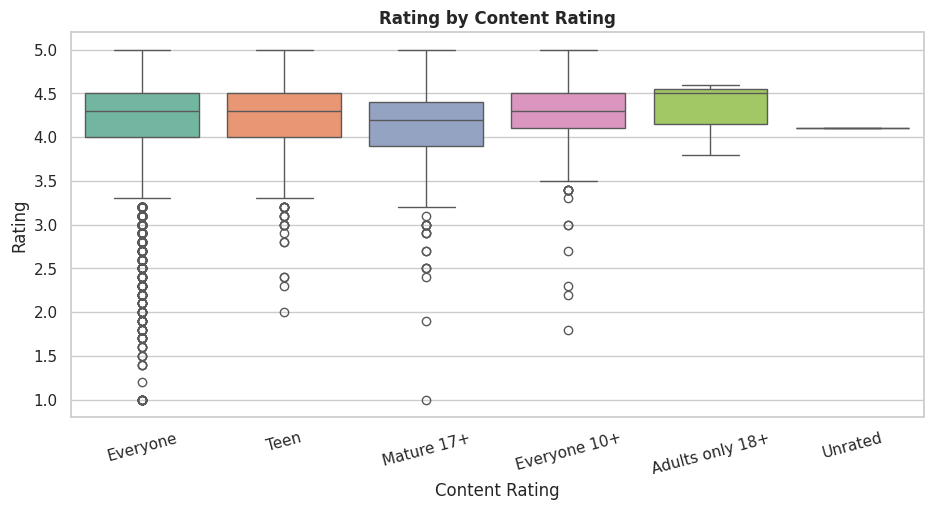

,mean,median,count
Content Rating,,,
Adults only 18+,4.300,4.500,3
Everyone,4.166,4.300,6618
Everyone 10+,4.226,4.300,305
Mature 17+,4.122,4.200,357
Teen,4.226,4.300,912
Unrated,4.100,4.100,1


In [27]:
order = df['Content Rating'].value_counts().index
plt.figure(figsize=(11, 5))
sns.boxplot(data=df.dropna(subset=['Rating']), x='Content Rating', y='Rating', order=order, palette='Set2')
plt.xticks(rotation=15); plt.title('Rating by Content Rating'); plt.show()
df.groupby('Content Rating')['Rating'].agg(['mean','median','count'])

**Insight:** Medians are nearly identical across groups (~4.3). *Mature 17+* has the lowest mean (≈4.12); *Adults only 18+* has just 3 apps, so don't over-read it.

### Q5. Genres with the most apps over 1 million installs

Apps with > 1M installs: 1981


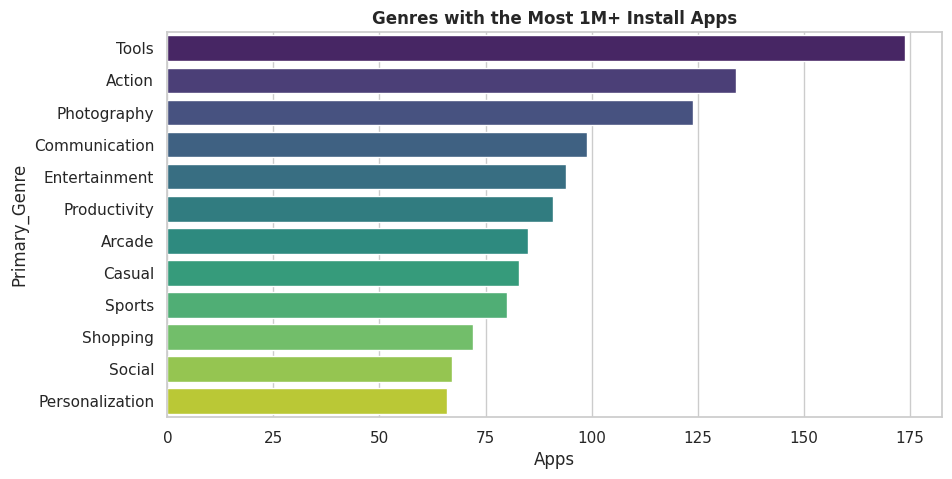

,apps,big,hit_rate_%
Primary_Genre,,,
Photography,281,124,44.128
Racing,108,47,43.519
Action,311,134,43.087
Arcade,199,85,42.714
Strategy,99,38,38.384
Casual,225,83,36.889
Shopping,202,72,35.644
Video Players & Editors,165,53,32.121
Communication,316,99,31.329


In [28]:
big = df[df['Installs'] > 1_000_000]
print('Apps with > 1M installs:', len(big))
g = big['Primary_Genre'].value_counts().head(12)
sns.barplot(x=g.values, y=g.index, palette='viridis')
plt.title('Genres with the Most 1M+ Install Apps'); plt.xlabel('Apps'); plt.show()

# Hit-rate: share of each genre's apps that exceed 1M installs (more fair than raw counts)
hit = (df.groupby('Primary_Genre')
         .agg(apps=('App','count'), big=('Installs', lambda s: (s > 1_000_000).sum())))
hit['hit_rate_%'] = hit['big'] / hit['apps'] * 100
hit[hit['apps'] >= 30].sort_values('hit_rate_%', ascending=False).head(10)

**Insight:** By raw count *Tools (174), Action, Photography, Communication and Entertainment* lead. By **hit-rate** (share of a genre's apps that cross 1M) *Photography (44%), Racing, Action and Arcade* are the most 'winnable' – roughly 4 in 10 apps get there.

### Q6. How frequently do apps get updated?

In [29]:
print('Each app has only ONE `Last Updated` date in this dataset, so the gap between *consecutive* updates')
print('cannot be computed directly. Proxy: days since last update, relative to the dataset snapshot date.\n')

snapshot = df['Last Updated'].max()
df['Days_Since_Update'] = (snapshot - df['Last Updated']).dt.days
print('Snapshot date:', snapshot.date())
print(df['Days_Since_Update'].describe())

fresh = pd.cut(df['Days_Since_Update'], [-1, 30, 90, 180, 365, 10_000],
               labels=['<=1 month','1-3 months','3-6 months','6-12 months','>1 year']).value_counts(normalize=True).sort_index()
print('\nShare of apps by update recency:'); print((fresh*100).round(1))

(df.groupby('Category')['Days_Since_Update'].median().sort_values().head(8)
   .rename('Median days since last update'))

Each app has only ONE `Last Updated` date in this dataset, so the gap between *consecutive* updates
cannot be computed directly. Proxy: days since last update, relative to the dataset snapshot date.

Snapshot date: 2018-08-08
count   9,659.000
mean      281.011
std       406.722
min         0.000
25%        22.000
50%        96.000
75%       366.000
max     3,001.000
Name: Days_Since_Update, dtype: float64

Share of apps by update recency:
Days_Since_Update
<=1 month     30.400
1-3 months    18.900
3-6 months    12.000
6-12 months   13.700
>1 year       25.000
Name: proportion, dtype: float64


Category
Dating               20.000
Shopping             21.500
House And Home       27.000
Entertainment        31.000
Food And Drink       36.000
Auto And Vehicles    36.000
Comics               36.000
Health And Fitness   38.000
Name: Median days since last update, dtype: float64

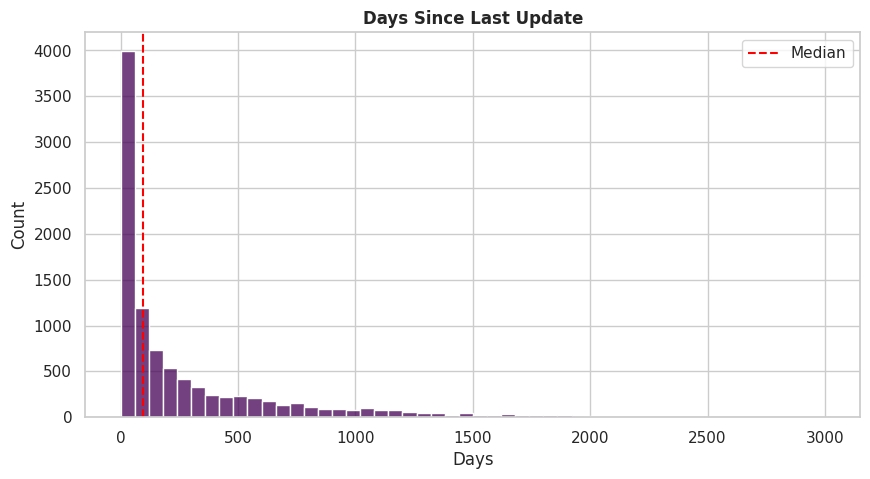

,avg_rating,median_installs,apps
Recency,,,
<=3 months,4.247,"1,000,000.000",4253
3-12 months,4.131,"100,000.000",1935
>1 year,4.058,"10,000.000",2008


In [30]:
sns.histplot(df['Days_Since_Update'], bins=50, color='#440154')
plt.axvline(df['Days_Since_Update'].median(), color='red', ls='--', label='Median')
plt.title('Days Since Last Update'); plt.xlabel('Days'); plt.legend(); plt.show()

# Do fresher apps do better?
sub = df.dropna(subset=['Rating'])
sub['Recency'] = pd.cut(sub['Days_Since_Update'], [-1, 90, 365, 10_000], labels=['<=3 months','3-12 months','>1 year'])
sub.groupby('Recency', observed=True).agg(avg_rating=('Rating','mean'), median_installs=('Installs','median'), apps=('App','count'))

**Insight:** The median app was last updated ~96 days before the snapshot (about 3 months); 30% were updated within the last month, while 25% had not been touched for over a year. **Apps updated within 3 months have a median of 1M installs vs 10K for apps not updated in over a year** (and ratings of 4.25 vs 4.06). This is correlation, not proof of cause – popular apps have more resources to update – but regular updates clearly go hand-in-hand with success.

### Q7. Impact of app size on installs

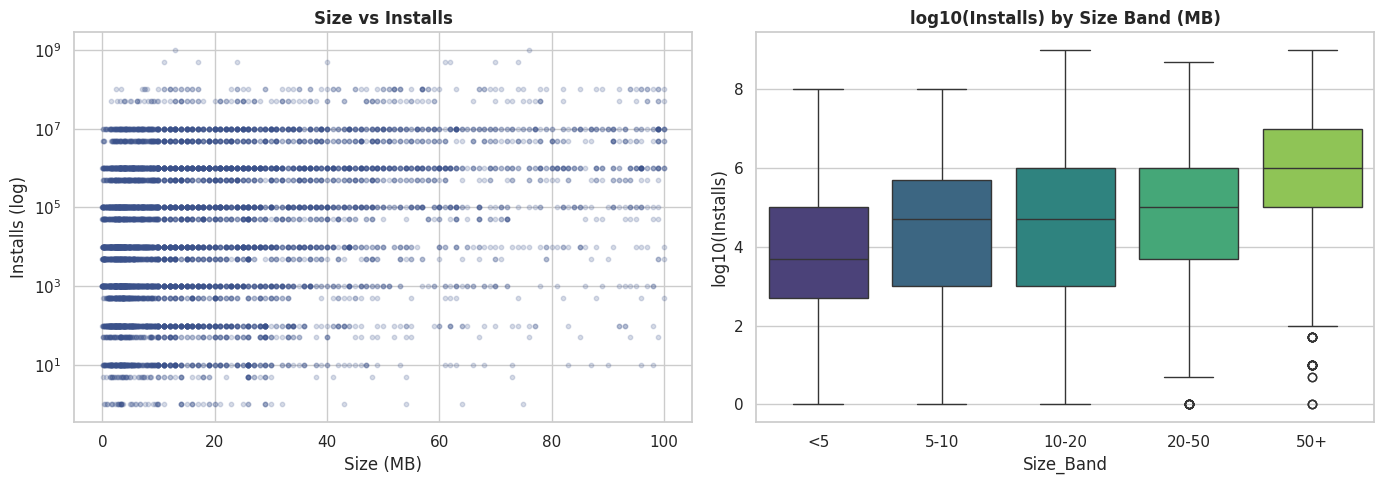

Spearman(size, installs): 0.31


,apps,median_installs,avg_rating
Size_Band,,,
<5,2317,"5,000.000",4.113
5-10,1613,"10,000.000",4.156
10-20,1533,"50,000.000",4.173
20-50,2092,"100,000.000",4.162
50+,876,"1,000,000.000",4.251


In [31]:
sub = df.dropna(subset=['Size_MB'])
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(sub['Size_MB'], sub['Installs'], alpha=.2, s=10, color='#3b528b')
ax[0].set_yscale('log'); ax[0].set_xlabel('Size (MB)'); ax[0].set_ylabel('Installs (log)'); ax[0].set_title('Size vs Installs')

sub['Size_Band'] = pd.cut(sub['Size_MB'], [0, 5, 10, 20, 50, 200], labels=['<5','5-10','10-20','20-50','50+'])
sns.boxplot(data=sub, x='Size_Band', y='Log_Installs', ax=ax[1], palette='viridis')
ax[1].set_title('log10(Installs) by Size Band (MB)'); ax[1].set_ylabel('log10(Installs)')
plt.tight_layout(); plt.show()

print('Spearman(size, installs):', round(sub['Size_MB'].corr(sub['Installs'], method='spearman'), 3))
sub.groupby('Size_Band', observed=True).agg(apps=('App','count'), median_installs=('Installs','median'), avg_rating=('Rating','mean'))

**Insight:** There is a **moderate positive link (Spearman ≈ 0.31)**: median installs climb from 5K (<5 MB) to 1M (50+ MB). Bigger apps are not penalised – they tend to be richer products from better-resourced teams. Size alone doesn't cause installs, but there is no evidence that shrinking features to save MBs helps.

### Q8. Highest-reviewed apps and their ratings

,App,Category,Reviews,Rating,Installs
1873,Facebook,Social,78158306,4.100,1000000000
279,WhatsApp Messenger,Communication,69119316,4.400,1000000000
1914,Instagram,Social,66577446,4.500,1000000000
304,Messenger – Text and Video Chat for Free,Communication,56646578,4.000,1000000000
1355,Clash of Clans,Game,44893888,4.600,100000000
3021,Clean Master- Space Cleaner & Antivirus,Tools,42916526,4.700,500000000
1350,Subway Surfers,Game,27725352,4.500,1000000000
2749,YouTube,Video Players,25655305,4.300,1000000000
6381,"Security Master - Antivirus, VPN, AppLock, Boo...",Tools,24900999,4.700,500000000
1354,Clash Royale,Game,23136735,4.600,100000000


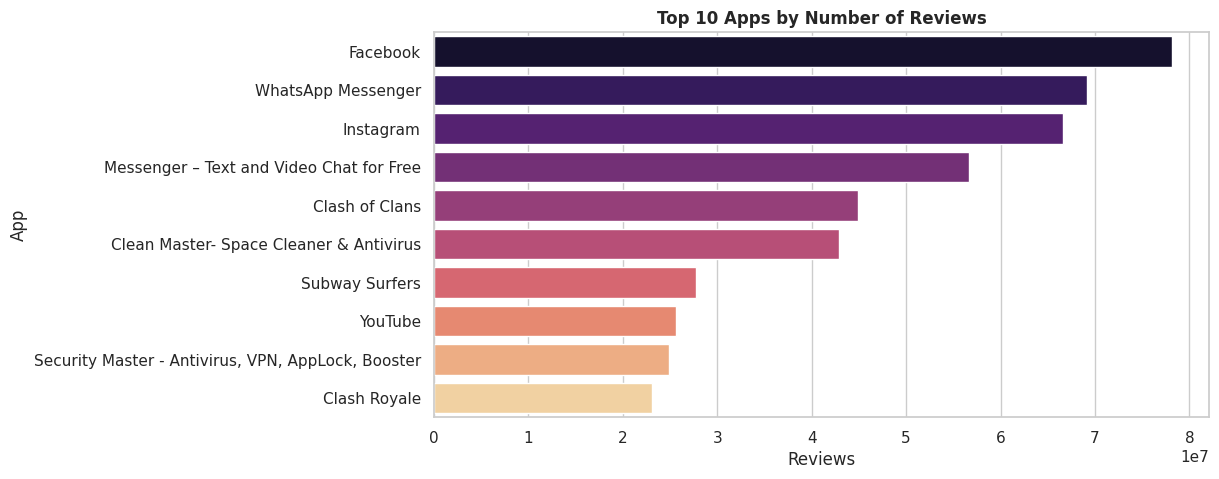

Average rating of these 10 apps: 4.44


In [32]:
top_rev = df.sort_values('Reviews', ascending=False)[['App','Category','Reviews','Rating','Installs']].head(10)
display(top_rev)
sns.barplot(data=top_rev, y='App', x='Reviews', palette='magma')
plt.title('Top 10 Apps by Number of Reviews'); plt.show()
print('Average rating of these 10 apps:', round(top_rev['Rating'].mean(), 2))

**Insight:** The most-reviewed apps are social/communication apps, mass-market games (Clash of Clans, Subway Surfers) and utility apps (Clean Master, Security Master), all rated **4.0–4.7** (average ≈ 4.44) – reaching huge scale *with* good quality.

### Q9. Content rating distribution: Free vs Paid

Type,Free,Paid
Content Rating,,
Adults only 18+,3,0
Everyone,7250,653
Everyone 10+,291,31
Mature 17+,375,18
Teen,984,52
Unrated,2,0


Type,Free,Paid
Content Rating,,
Adults only 18+,0.000,0.000
Everyone,81.400,86.600
Everyone 10+,3.300,4.100
Mature 17+,4.200,2.400
Teen,11.000,6.900
Unrated,0.000,0.000


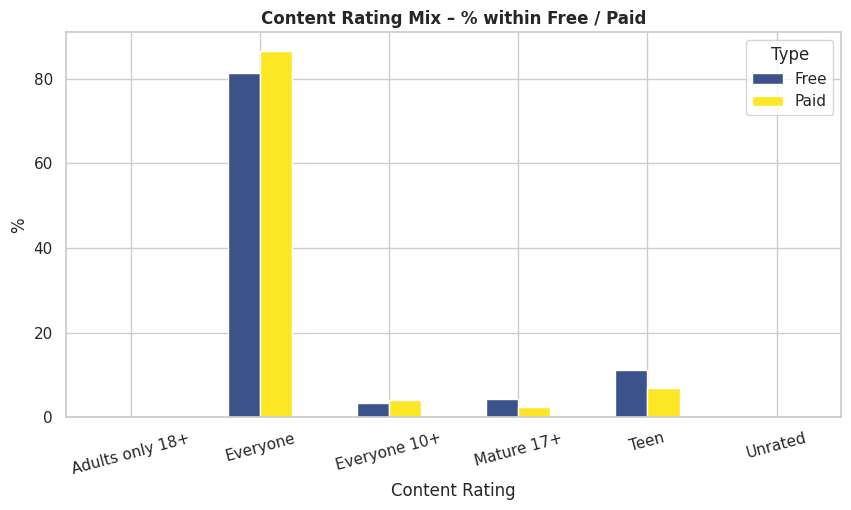

In [33]:
ct = pd.crosstab(df['Content Rating'], df['Type'])
display(ct)
ct_pct = pd.crosstab(df['Content Rating'], df['Type'], normalize='columns') * 100
display(ct_pct.round(1))
ct_pct.plot(kind='bar', figsize=(10, 5), color=['#3b528b', '#fde725'])
plt.title('Content Rating Mix – % within Free / Paid'); plt.ylabel('%'); plt.xticks(rotation=15); plt.show()

**Insight:** Both are mostly *Everyone* (81% of free, 87% of paid). Free apps carry proportionally more **Teen (11% vs 7%) and Mature 17+ (4.2% vs 2.4%)** content – ad-supported entertainment/social apps skew older, while paid apps are mostly general-audience utilities and education.

### Q10. Top 5 categories by installs

Category
Game            13.500
Communication   11.000
Tools            8.100
Family           6.200
Productivity     5.800
Name: Installs (billions), dtype: float64


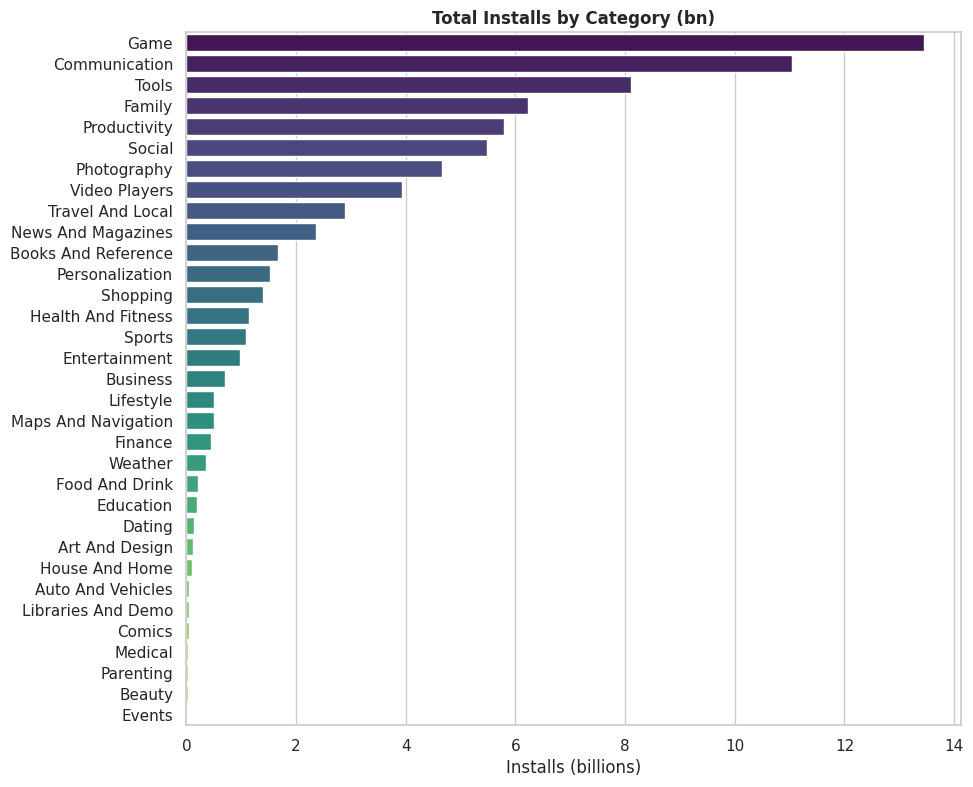

In [34]:
cat_inst = df.groupby('Category')['Installs'].sum().sort_values(ascending=False)
print((cat_inst.head(5) / 1e9).round(1).rename('Installs (billions)'))
plt.figure(figsize=(10, 9))
sns.barplot(x=cat_inst.values / 1e9, y=cat_inst.index, palette='viridis')
plt.title('Total Installs by Category (bn)'); plt.xlabel('Installs (billions)'); plt.ylabel(''); plt.show()

**Insight:** **Game (13.5bn), Communication (11.0bn), Tools (8.1bn), Family (6.2bn) and Productivity (5.8bn)** account for the biggest slice of installs – the 'demand heavyweights'.

## 7. Advanced-Level Questions

### Q1. Top 10 highest-rated apps – reviews & installs compared

In [35]:
rated = df.dropna(subset=['Rating'])
print('Apps with a perfect 5.0 rating:', (rated['Rating'] == 5).sum())
print('Median reviews of those 5.0 apps:', rated.loc[rated['Rating'] == 5, 'Reviews'].median())
print('Median installs of those 5.0 apps:', rated.loc[rated['Rating'] == 5, 'Installs'].median())

Apps with a perfect 5.0 rating: 271
Median reviews of those 5.0 apps: 4.0
Median installs of those 5.0 apps: 100.0


⚠️ **A naive "top 10 by rating" is misleading** – hundreds of apps tie at 5.0, mostly with a handful of reviews. We show it, and then a *reliable* version that requires **≥ 1,000 reviews**.

In [36]:
naive = rated.sort_values(['Rating','Reviews'], ascending=False)[['App','Category','Rating','Reviews','Installs']].head(10)
print('NAIVE top 10 (ties broken by reviews):'); display(naive)

reliable = (rated[rated['Reviews'] >= 1000]
            .sort_values(['Rating','Reviews'], ascending=False)
            [['App','Category','Rating','Reviews','Installs']].head(10))
print('RELIABLE top 10 (>= 1,000 reviews):'); display(reliable)

NAIVE top 10 (ties broken by reviews):


,App,Category,Rating,Reviews,Installs
9178,Ríos de Fe,Lifestyle,5.000,141,1000
9122,"FD Calculator (EMI, SIP, RD & Loan Eligilibility)",Finance,5.000,104,1000
6896,Oración CX,Lifestyle,5.000,103,5000
5678,Barisal University App-BU Face,Family,5.000,100,1000
8318,Master E.K,Family,5.000,90,1000
6351,CL REPL,Tools,5.000,47,1000
4139,AJ Cam,Photography,5.000,44,100
4106,AI Today : Artificial Intelligence News & AI 101,News And Magazines,5.000,43,100
6681,CS & IT Interview Questions,Family,5.000,43,1000
8339,Ek Vote,Productivity,5.000,43,500


RELIABLE top 10 (>= 1,000 reviews):


,App,Category,Rating,Reviews,Installs
8447,JW Library,Books And Reference,4.900,922752,10000000
937,Six Pack in 30 Days - Abs Workout,Health And Fitness,4.900,272337,10000000
75,Tickets + PDA 2018 Exam,Auto And Vehicles,4.900,197136,1000000
531,"Learn Japanese, Korean, Chinese Offline & Free",Education,4.900,133136,1000000
976,StrongLifts 5x5 Workout Gym Log & Personal Tra...,Health And Fitness,4.900,66791,1000000
5851,PixPanda - Color by Number Pixel Art Coloring ...,Family,4.900,55723,1000000
95,"ipsy: Makeup, Beauty, and Tips",Beauty,4.900,49790,1000000
2969,Hungry Hearts Diner: A Tale of Star-Crossed Souls,Family,4.900,46253,500000
935,Lose Belly Fat in 30 Days - Flat Stomach,Health And Fitness,4.900,38098,5000000
3892,Solitaire: Decked Out Ad Free,Game,4.900,37302,500000


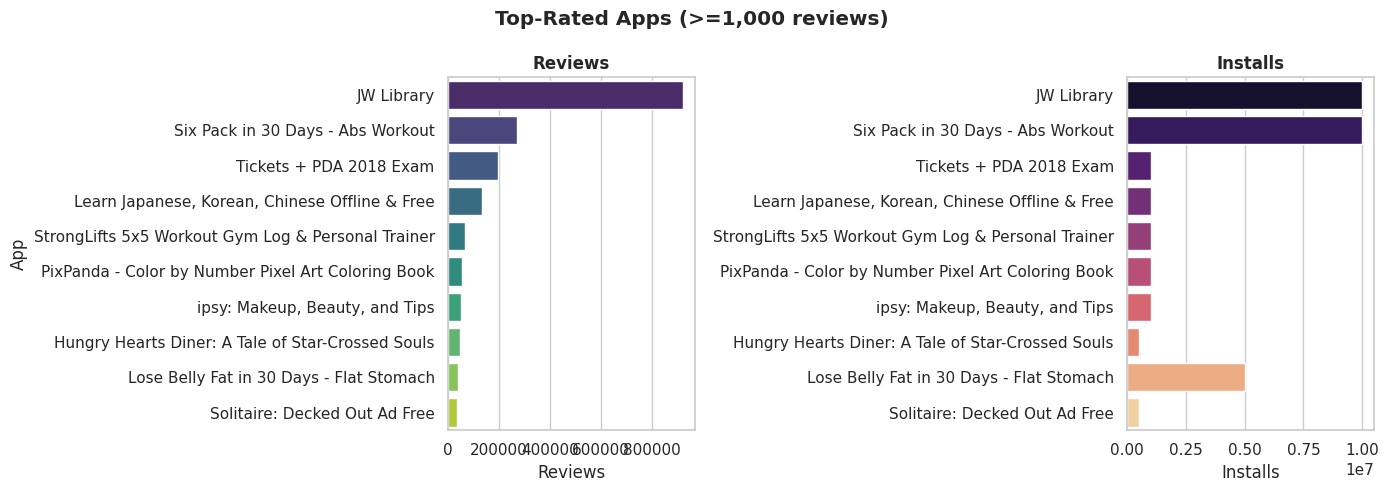

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=reliable, y='App', x='Reviews', ax=ax[0], palette='viridis'); ax[0].set_title('Reviews')
sns.barplot(data=reliable, y='App', x='Installs', ax=ax[1], palette='magma');  ax[1].set_title('Installs')
ax[1].set_ylabel(''); plt.suptitle('Top-Rated Apps (>=1,000 reviews)', fontweight='bold'); plt.tight_layout(); plt.show()

**Insight:** Perfect ratings are mostly an artefact of tiny samples. Among apps with real review volume, top-rated apps still have modest installs, so quality alone is not enough – discoverability and marketing matter.

### Q2. Trend of app updates over time & seasonality

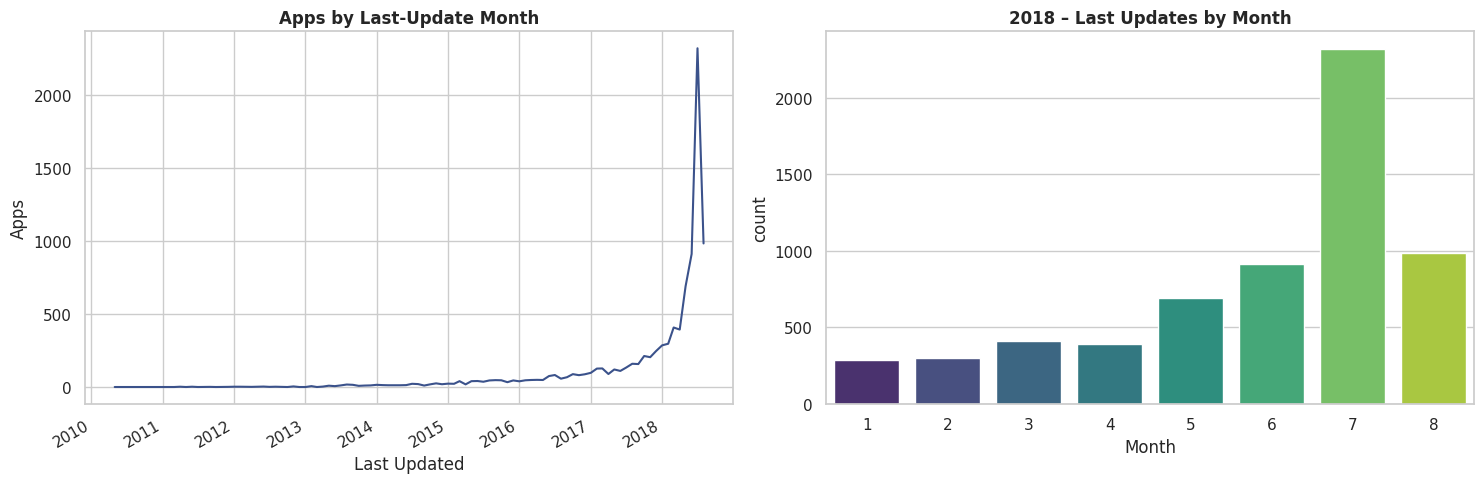

Share of all apps whose last update fell in 2018: 65.1%
Share updated in Jun-Aug 2018: 43.6%


In [38]:
monthly = df.groupby(df['Last Updated'].dt.to_period('M'))['App'].count()
monthly.index = monthly.index.to_timestamp()
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
monthly.plot(ax=ax[0], color='#3b528b'); ax[0].set_title('Apps by Last-Update Month'); ax[0].set_ylabel('Apps')

recent = df[df['Update_Year'] == 2018]
sns.countplot(data=recent, x='Update_Month', ax=ax[1], palette='viridis')
ax[1].set_title('2018 – Last Updates by Month'); ax[1].set_xlabel('Month')
plt.tight_layout(); plt.show()

print('Share of all apps whose last update fell in 2018:', f'{(df["Update_Year"]==2018).mean():.1%}')
print('Share updated in Jun-Aug 2018:', f'{((df["Update_Year"]==2018) & df["Update_Month"].between(6,8)).sum()/len(df):.1%}')

**Insight:** The counts explode toward mid-2018 (the scrape date) – this is a *snapshot effect*: every app shows its **latest** update, so recent months look busiest. We therefore **cannot claim true seasonality** from this single snapshot; a proper seasonality study needs each app's full update history.

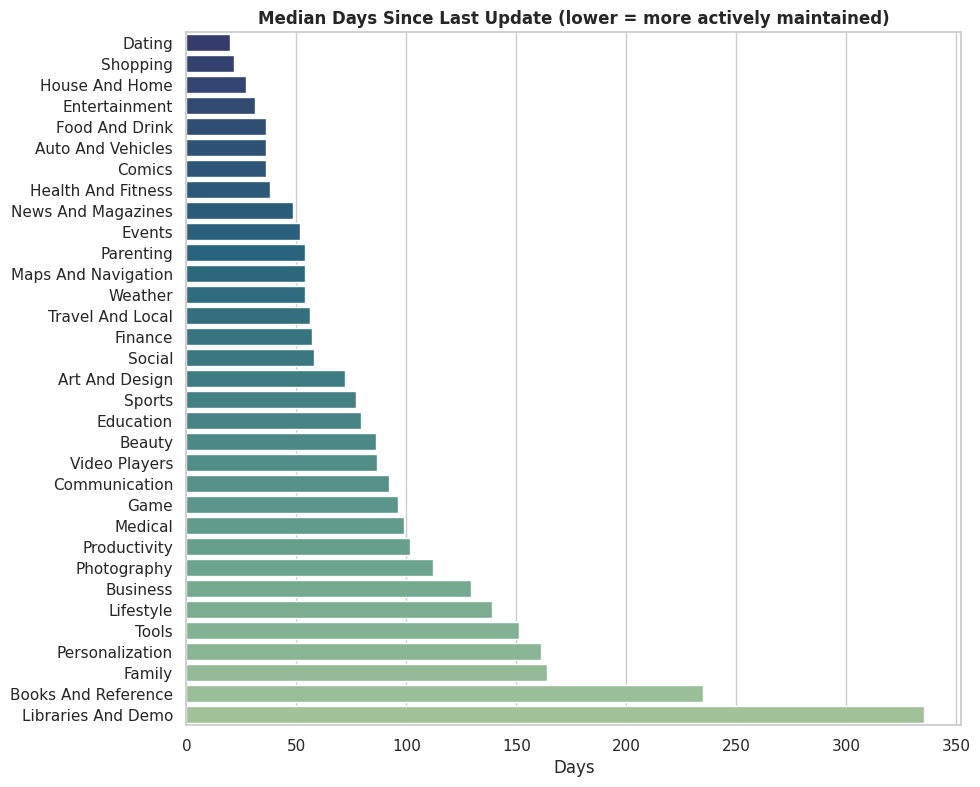

In [39]:
# Update recency by category (median days since update) - which categories are maintained most actively?
act = df.groupby('Category')['Days_Since_Update'].median().sort_values()
plt.figure(figsize=(10, 9))
sns.barplot(x=act.values, y=act.index, palette='crest_r')
plt.title('Median Days Since Last Update (lower = more actively maintained)'); plt.xlabel('Days'); plt.ylabel('')
plt.show()

### Q3. Average rating by install bins

,mean,median,count
Install_Bin,,,
10+,4.625,5.000,69
50+,4.420,5.000,56
100+,4.364,4.700,302
500+,4.178,4.400,199
1K+,4.065,4.300,696
5K+,4.021,4.200,425
10K+,4.035,4.200,986
50K+,4.045,4.100,457
100K+,4.116,4.200,1095


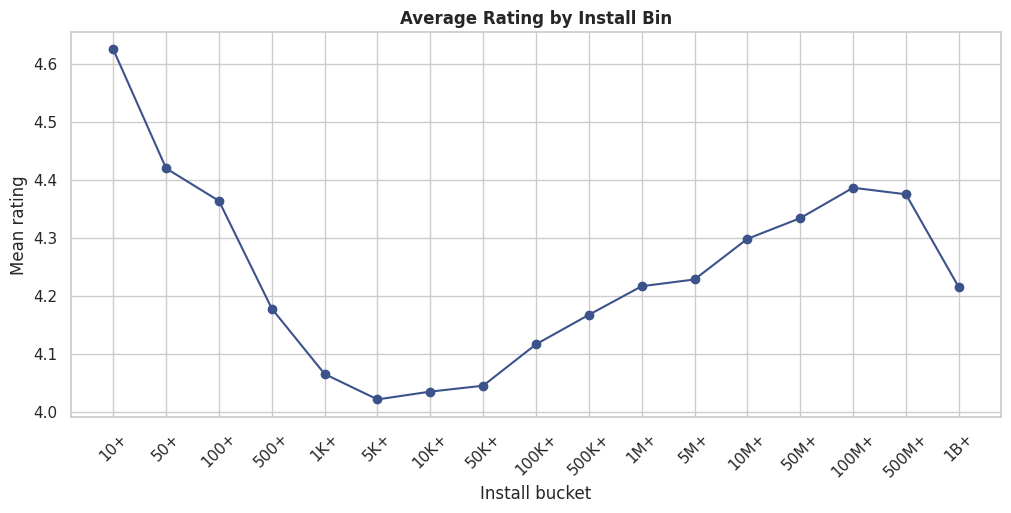

In [40]:
labels = {10:'10+',50:'50+',100:'100+',500:'500+',1000:'1K+',5000:'5K+',10000:'10K+',50000:'50K+',100000:'100K+',
          500000:'500K+',1000000:'1M+',5000000:'5M+',10000000:'10M+',50000000:'50M+',100000000:'100M+',
          500000000:'500M+',1000000000:'1B+'}
rated = df.dropna(subset=['Rating']).copy()
order = [labels[k] for k in sorted(labels) if k in set(rated['Installs'])]
rated['Install_Bin'] = rated['Installs'].map(labels)
rated['Install_Bin'] = pd.Categorical(rated['Install_Bin'], categories=order, ordered=True)

binned = rated.groupby('Install_Bin', observed=True)['Rating'].agg(['mean','median','count'])
display(binned)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(binned.index.astype(str), binned['mean'], marker='o', color='#3b528b')
ax.set_title('Average Rating by Install Bin'); ax.set_ylabel('Mean rating'); ax.set_xlabel('Install bucket')
plt.xticks(rotation=45); plt.show()

**Insight:** The relationship is **U-shaped**. Apps with <500 installs have inflated ratings (4.4–4.6) – a handful of friendly early raters. Ratings then fall to a **trough of ≈4.02–4.05 at 1K–50K installs** (the 'reality check' zone once strangers start rating) and climb steadily to **≈4.3–4.4 at 10M+**. Apps that reach scale are generally the ones users like; the 1K–50K phase is where weak apps get exposed.

### Q4. Sentiment analysis on reviews

⚠️ **`googleplaystore.csv` contains NO review text** – only the *count* of reviews – so sentiment analysis cannot be done on this file alone.

The Kaggle dataset ships a companion file, **`googleplaystore_user_reviews.csv`**, which has `App`, `Translated_Review`, `Sentiment`, `Sentiment_Polarity`. The cell below runs **only if you upload that file**; otherwise it is skipped safely.

In [41]:
UR_PATH = 'googleplaystore_user_reviews.csv'
if not os.path.exists(UR_PATH):
    try:
        from google.colab import files
        print('Optional: upload googleplaystore_user_reviews.csv (or Cancel to skip)')
        up = files.upload()
        if up: UR_PATH = list(up.keys())[0]
    except Exception:
        pass

if os.path.exists(UR_PATH):
    ur = pd.read_csv(UR_PATH).dropna(subset=['Translated_Review', 'Sentiment_Polarity'])
    print('Review rows:', len(ur))
    print(ur['Sentiment'].value_counts(normalize=True).round(3))

    app_sent = ur.groupby('App').agg(avg_polarity=('Sentiment_Polarity','mean'), n=('App','count')).reset_index()
    m = app_sent.merge(df[['App','Rating','Category']], on='App').dropna()
    print('\nCorrelation: avg sentiment polarity vs Rating =', round(m['avg_polarity'].corr(m['Rating']), 3))

    # Common themes: most frequent words in positive vs negative reviews
    from collections import Counter
    import re
    stop = set('the a an and is it to of i this app for in my that you with was are be on have but not so just can very its as at me they if all your do from or one get use'.split())
    def top_words(text_series, k=15):
        words = re.findall(r'[a-z]{3,}', ' '.join(text_series).lower())
        return Counter(w for w in words if w not in stop).most_common(k)
    print('\nTop words in POSITIVE reviews:', top_words(ur.loc[ur['Sentiment']=='Positive','Translated_Review']))
    print('Top words in NEGATIVE reviews:', top_words(ur.loc[ur['Sentiment']=='Negative','Translated_Review']))
else:
    print('Skipped – review-text file not provided.')

Skipped – review-text file not provided.


### Q5. Genre vs user ratings – mean & median

Genres with >= 20 rated apps: 47


,mean,median,std,apps,group
Primary_Genre,,,,,
Events,4.436,4.500,0.419,45,Highest
Puzzle,4.371,4.400,0.337,123,Highest
Art & Design,4.350,4.400,0.363,62,Highest
Books & Reference,4.343,4.500,0.439,171,Highest
Personalization,4.332,4.400,0.359,298,Highest
Word,4.318,4.300,0.306,22,Highest
Parenting,4.300,4.400,0.518,50,Highest
Education,4.294,4.400,0.575,498,Highest
Entertainment,4.093,4.200,0.551,502,Lowest


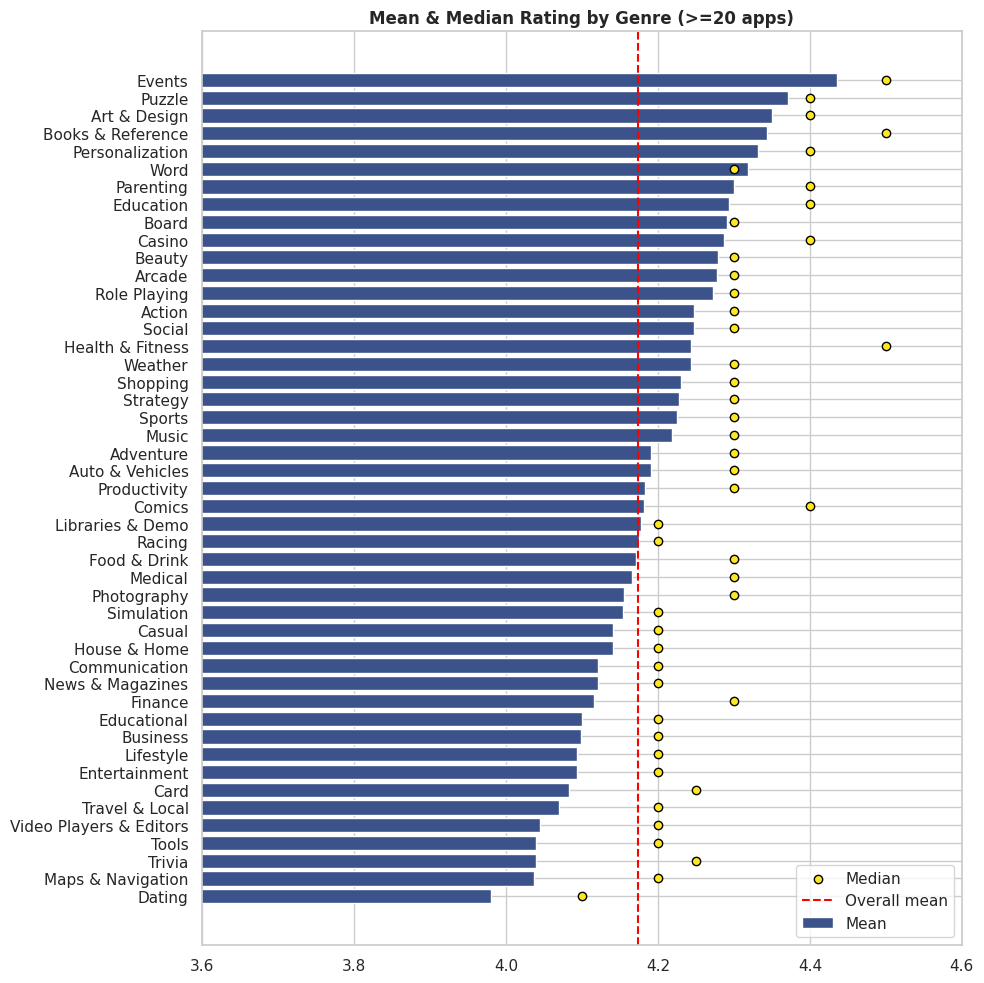

In [42]:
gen = (df.dropna(subset=['Rating']).groupby('Primary_Genre')['Rating']
         .agg(mean='mean', median='median', std='std', apps='count'))
gen = gen[gen['apps'] >= 20].sort_values('mean', ascending=False)   # ignore tiny genres
print('Genres with >= 20 rated apps:', len(gen))
display(pd.concat([gen.head(8).assign(group='Highest'), gen.tail(8).assign(group='Lowest')]))

fig, ax = plt.subplots(figsize=(10, 10))
y = np.arange(len(gen))
ax.barh(y, gen['mean'], color='#3b528b', label='Mean')
ax.scatter(gen['median'], y, color='#fde725', edgecolor='k', zorder=3, label='Median')
ax.set_yticks(y); ax.set_yticklabels(gen.index); ax.invert_yaxis()
ax.set_xlim(3.6, 4.6); ax.axvline(df['Rating'].mean(), color='red', ls='--', label='Overall mean')
ax.set_title('Mean & Median Rating by Genre (>=20 apps)'); ax.legend(); plt.tight_layout(); plt.show()

**Insight:** **Highest:** Events (4.44), Puzzle (4.37), Art & Design, Books & Reference, Personalization. **Lowest:** Dating (3.98), Maps & Navigation, Trivia, Tools, Video Players, Travel & Local. Education has a high median (4.4) but the widest spread (std 0.58), so quality varies a lot there. Dating/Navigation apps solve harder, higher-stakes problems, so **expectation gaps** probably drive lower scores (hypothesis – not testable from this data).

### Bonus: What separates high-rated (4.5+) from lower-rated apps?

In [43]:
r = df.dropna(subset=['Rating']).copy()
r['High_Rated'] = r['Rating'] >= 4.5
cmp = r.groupby('High_Rated').agg(
    apps=('App','count'),
    median_installs=('Installs','median'),
    median_reviews=('Reviews','median'),
    median_size_mb=('Size_MB','median'),
    pct_paid=('Is_Free', lambda s: (~s).mean()*100),
    median_days_since_update=('Days_Since_Update','median'))
cmp

,apps,median_installs,median_reviews,median_size_mb,pct_paid,median_days_since_update
High_Rated,,,,,,
False,5646,"100,000.000","2,833.500",13.000,6.022,103.000
True,2550,"100,000.000","3,588.000",13.000,10.275,56.000


## 8. Key Insights & Recommendations

### 🔑 Key findings
1. **Ratings are high but not differentiating.** Mean 4.17 / median 4.30; 77% of rated apps score ≥ 4.0. Benchmark new apps against **4.3+**.
2. **Popularity ≠ quality.** Installs vs rating correlation is ≈ 0.03–0.08. Ratings are U-shaped across install buckets (inflated for tiny apps, trough at 1K–50K installs, ≈4.3–4.4 at 10M+).
3. **Demand is concentrated.** Game, Communication, Tools, Family and Productivity hold the most installs; Family, Game and Tools have the most apps. Photography, Racing, Action and Arcade have the highest hit-rate (~43-44% of apps pass 1M installs).
4. **Free dominates (92%) and earns far more engagement** (mean 234K vs 8.7K reviews). Paid apps are rated slightly higher (4.26 vs 4.17) but ratings dip above $10.
5. **Maintenance matters.** Apps updated in the last 3 months: median 1M installs, 4.25 rating. Not updated for 1+ year: 10K installs, 4.06 rating. Highly rated apps (4.5+) were updated ~2x more recently (56 vs 103 days median).
6. **Size is not a barrier.** Bigger apps have higher median installs (moderate correlation ≈ 0.31). Games average ~42 MB, Tools ~9 MB.
7. **Content rating:** "Everyone" covers ~82% of apps and has no rating penalty; Mature 17+ rates lowest (≈4.12).
8. **Category / genre ratings:** Events, Art & Design, Education, Books & Reference, Personalization and Puzzle rate highest; Dating, Maps & Navigation and Tools rate lowest.

### ✅ Recommendations by stakeholder
| Stakeholder | Recommendation | Evidence |
|---|---|---|
| **Product / Senior Mgmt** | Target **Everyone**-rated apps in high-demand categories (Games, Communication, Productivity); consider high-satisfaction niches (Education, Art & Design, Books & Reference, Events) where competition is thinner | Categories 1-3 above |
| **Developers** | Ship an update at least every ~3 months; track "days since last update" as a health KPI | Finding 5 |
| **Developers** | Don't cut features just to shrink the install size; keep utility apps lean (~10 MB), games can be heavy | Finding 6 |
| **Product / Monetisation** | Default to **free + ads/in-app purchases**; if paid, price under ~$5-10 and justify the price with value | Finding 4 |
| **Marketing** | The 1K–50K installs stage is where ratings dip – invest in onboarding, in-app rating prompts at positive moments, and responding to reviews to protect rating during growth | Finding 2 |
| **Marketing / Advertisers** | Use reviews as an engagement KPI (≈0.97 correlation with installs); the big audiences sit in Communication, Game and Tools | Finding 3 |
| **Partners / Analytics** | Collect full update history, review text and revenue data to move from correlation to causation | Limitations below |

> ⚠️ These are **associations, not proven causes** – observational data from one snapshot (Aug 2018).

## 9. Limitations & Next Steps
- **Install counts are bucketed** (e.g., `1,000,000+`) – real installs are unknown; we used the bucket lower bound.
- **One snapshot in time** – each app has a single `Last Updated`; true update frequency/seasonality needs historical data.
- **Ratings are self-selected** and missing for ~15% of apps; apps with few reviews have unreliable ratings.
- **No revenue data** – we can't measure monetisation directly.
- **Review text not in this file** – use `googleplaystore_user_reviews.csv` for sentiment (Advanced Q4).
- **Next steps:** build a model (e.g., Random Forest) to predict `High_Rated`; run an A/B test on update cadence; collect time-series data.

